# TPI Análisis de Datos - Grupo 2

## Integrantes

- Gonzalo Suarez
- Alejo Nehuén Paiva
- Tomás Barrios
- Agustina Anabel Seggiaro

---
## consignas

---



### Visualización de Datos

Construcción de un reporte gráfico utilizando **Matplotlib** y **Seaborn** que incluya:

- Histogramas/KDE de la antigüedad (`tenure`) y cargos mensuales (`MonthlyCharges`).
- Representación gráfica de la matriz de correlación (Heatmap).
- Diagramas de barras comparativos para evaluar la tasa de cancelación (`Churn`) según variables categóricas (tipo de contrato y modalidad de pago).

> Cada gráfico debe estar acompañado por una breve interpretación analítica orientada al impacto en el negocio.

---

## C. Preprocesamiento y Modelado Predictivo

### Preprocesamiento de Datos para Modelado

- Transformación de variables categóricas mediante codificación nominal (One-Hot Encoding) u ordinal (Label / Ordinal Encoding).
- Normalización o estandarización de atributos cuantitativos (`StandardScaler` / `MinMaxScaler`).
- Partición estratificada en conjuntos de entrenamiento y evaluación (`train_test_split`, proporción 80/20).

### Predicción Numérica: Modelos de Regresión

Entrenamiento de un modelo básico de **Regresión Lineal Simple** para estimar una variable continua (por ejemplo, `TotalCharges`). Evaluación simple mediante el coeficiente de determinación **R²** y el Error Medio Absoluto (**MAE**).

### Predicción Categórica: Modelos de Clasificación

Entrenamiento de un único modelo de clasificación elemental (por ejemplo, Regresión Logística o Árbol de Decisión) para predecir la variable binaria `Churn`. Evaluación básica mediante la **Matriz de Confusión** y la métrica de **Exactitud (Accuracy)**.

---

## D. Reproducibilidad y Buenas Prácticas

Uso riguroso de control de versiones **Git** con mensajes de confirmación (commits) descriptivos, estructuración limpia del repositorio, archivo `README.md` explicativo y entorno reproducible en **Google Colab**.


# Carga de datos

In [1]:
import pandas as pd

# df = pd.read_csv('/content/data.csv');

In [2]:
import numpy as np
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
import seaborn as sns

file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "blastchar/telco-customer-churn",
  file_path
)

print("First 5 records:")
print(df.head())
print("\n")
print("---------------------------------------------------------------------\n")
print(df.describe())
print("---------------------------------------------------------------------\n")
print("Forma del dataset: ")
print(df.shape)
print("---------------------------------------------------------------------\n")
print("Columnas: ")
lista = df.columns.tolist()
print(lista)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
First 5 records:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic            

# Primer contacto con los datos

In [3]:
from IPython.display import display

#display -> genera tabla print -> retorna texto

def titulo(texto):
    print(f"\n{'=' * 60}\n{texto}\n{'=' * 60}")

titulo("PRIMERAS 5 FILAS")
display(df.head())

titulo("ULTIMAS 5 FILAS")
display(df.tail())

titulo("DIMENSIONES")
print(f"Filas x Columnas: {df.shape}")

titulo("NOMBRES DE LAS COLUMNAS")
print(df.columns.tolist())

titulo("INFORMACION GENERAL")
df.info()

titulo("TIPOS DE DATOS")
display(df.dtypes.to_frame("dtype"))

titulo("ESTADISTICAS DESCRIPTIVAS")
display(df.describe())


PRIMERAS 5 FILAS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



ULTIMAS 5 FILAS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No



DIMENSIONES
Filas x Columnas: (7043, 21)

NOMBRES DE LAS COLUMNAS
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

INFORMACION GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   Intern

,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



ESTADISTICAS DESCRIPTIVAS


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


---
# Significado cada columna

| Columna | Qué es | Valores |
|---|---|---|
| `customerID` | Identificador único del cliente | texto tipo `7590-VHVEG` |
| `gender` | Género | `Male` / `Female` |
| `SeniorCitizen` | Si es adulto mayor (65+) | `1` = sí, `0` = no (ojo: acá es número, no `Yes`/`No`) |
| `Partner` | Si tiene pareja | `Yes` / `No` |
| `Dependents` | Si tiene personas a cargo (hijos, etc.) | `Yes` / `No` |
| `tenure` | Meses que lleva como cliente | número entero (0 a 72) |
| `PhoneService` | Si tiene servicio de telefonía | `Yes` / `No` |
| `MultipleLines` | Si tiene varias líneas telefónicas | `Yes` / `No` / `No phone service` |
| `InternetService` | Tipo de internet contratado | `DSL` / `Fiber optic` / `No` |
| `OnlineSecurity` | Si contrató seguridad online | `Yes` / `No` / `No internet service` |
| `OnlineBackup` | Si contrató backup en la nube | `Yes` / `No` / `No internet service` |
| `DeviceProtection` | Si contrató protección de dispositivos | `Yes` / `No` / `No internet service` |
| `TechSupport` | Si contrató soporte técnico | `Yes` / `No` / `No internet service` |
| `StreamingTV` | Si tiene streaming de TV | `Yes` / `No` / `No internet service` |
| `StreamingMovies` | Si tiene streaming de películas | `Yes` / `No` / `No internet service` |
| `Contract` | Tipo de contrato | `Month-to-month` / `One year` / `Two year` |
| `PaperlessBilling` | Si recibe factura digital (sin papel) | `Yes` / `No` |
| `PaymentMethod` | Método de pago | `Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)` |
| `MonthlyCharges` | Monto que paga por mes | decimal (float) |
| `TotalCharges` | Total acumulado que pagó desde que es cliente | viene como texto, hay que convertirlo |
| `Churn` | Si el cliente se dio de baja | `Yes` = se fue / `No` = sigue |


- **`Churn` es la variable "estrella"**: la mayoría de las preguntas de negocio giran en torno a quién se va y por qué.
- **Las columnas de servicios** (`OnlineSecurity`, `StreamingTV`, etc.) tienen una tercera categoría `No internet service`, así que no son solo `Yes`/`No`. Tenelo en cuenta cuando filtres.
- **`TotalCharges` es una trampa**: es texto y tiene algunos valores vacíos (clientes con `tenure` 0). Para hacer cuentas vas a tener que convertirla con `pd.to_numeric(..., errors='coerce')`. Eso te va a servir bastante para la parte de transformación.
---

In [4]:
# ----

In [5]:
# ----

---
# Manipulación de Datos

Manipulación de conjuntos de datos estructurados utilizando **Pandas** mediante:

- **Carga y Selección:** ingesta de datos y filtrado avanzado con múltiples condiciones lógicas (operadores `&`, `|`).
- **Agregación:** resumen estadístico y segmentación del negocio mediante `groupby`, combinando múltiples agregaciones (promedios, conteos, sumas).
- **Transformación Básica:** renombrado de columnas, eliminación de atributos irrelevantes y creación de columnas calculadas mediante operaciones aritméticas directas entre variables.
---


In [6]:
# Gonzalo ----
# -> no trabaja con el df original, solo copias del mismo,
# en la limpieza tocar el df original
# 1. Carga y Selección (filtros con & y |)

print("----------------------------Carga y Selección (filtros con & y |)----------------------------------\n")
#Ejemplo 1
# ¿Cuántos clientes adultos mayores que no tienen TechSupport o no tienen
# OnlineSecurity se dieron de baja? Mostrar la cantidad.
# (solo quienes tienen internet pero no contrataron el servicio)
es_senior = df["SeniorCitizen"] == 1
sin_contrato_soporte = df["TechSupport"] == "No"
sin_seguridad_online = df["OnlineSecurity"] == "No"
baja_de_servicio = df["Churn"] == "Yes"

resultado_punto_1 = df[ (es_senior) & ( (sin_contrato_soporte) | (sin_seguridad_online) ) & (baja_de_servicio) ].shape[0]
print(f"Cantidad de clientes que cumplen la condición: {resultado_punto_1}\n")

#Ejemplo 2
#Clientes que utilizan Streaming y el abono mensual, supera los 70usd.
clientes_streaming_alto_costo = df[(df['StreamingTV'] == 'Yes') & (df['MonthlyCharges'] > 70)]
print(f"Cantidad de clientes que usan StreamingTV y pagan más de 70usd: {len(clientes_streaming_alto_costo)}\n")

#-----

# 2. Agregación (resumen estadístico y segmentación con groupby)

print("-------------------Agregación (resumen estadístico y segmentación con groupby)--------------------\n")


#Ejemplo 1
# Para cada tipo de contrato, ¿cuántos clientes hay,
# cuál es el promedio del cargo mensual, cuál es la suma y el promedio del total acumulado?

df_agregacion = df.copy()
df_agregacion["TotalCharges"] = pd.to_numeric(df_agregacion["TotalCharges"], errors="coerce")

resumen_contratos = df_agregacion.groupby("Contract").agg(
    cantidad_clientes=("customerID", "count"),
    cargo_mensual_prom=("MonthlyCharges", "mean"),
    total_facturado=("TotalCharges", "sum"),
    total_prom=("TotalCharges", "mean")
).sort_values("total_facturado", ascending=False)

display(resumen_contratos.style.format(thousands=".", decimal=",", precision=2))

print("--------------------------------------------------------------\n")

#Ejemplo 2
#Permite ver cómo se comportan los ingresos y la cantidad de clientes combinando dos variables clave de contratación (Contract e InternetService)
agrupacion_contrato_internet = df.groupby(['Contract', 'InternetService']).agg(
    Cantidad_Clientes=('customerID', 'count'),
    Promedio_Mensual=('MonthlyCharges', 'mean'),
    Suma_Total_Ingresos=('TotalCharges', 'sum')
).reset_index()

display(agrupacion_contrato_internet.sort_values(by='Suma_Total_Ingresos'))

# 3. Transformación Básica
# Unificar los nombres de las columnas clave, descartar
# el identificador irrelevante (customerID) y calcular el
# cargo estimado según la antigüedad para compararlo con el
# cargo total real mediante una columna de diferencia.

print("----------------------------Transformación Básica----------------------------------\n")
df_transformado = df.copy()

df_transformado["TotalCharges"] = pd.to_numeric(df_transformado["TotalCharges"], errors="coerce").fillna(0)

renombres = {
    "tenure": "meses_antiguedad",
    "MonthlyCharges": "cargo_mensual",
    "TotalCharges": "cargo_total",
    'gender': 'Genero',
    'SeniorCitizen': 'AdultoMayor',
}

df_transformado = df_transformado.drop(columns=['customerID'])
df_transformado = df_transformado.rename(columns=renombres)

df_transformado["cargo_estimado"] = df_transformado["cargo_mensual"] * df_transformado["meses_antiguedad"]
df_transformado["diferencia_cargo"] = df_transformado["cargo_total"] - df_transformado["cargo_estimado"]

print(df_transformado["diferencia_cargo"].describe())

print("--------------------------------------------------------------\n")
#Ejemplo 2
# .replace(0, 1) en 'meses_antiguedad' para evitar un error de división por cero en clientes nuevos (mes 0).
df_transformado['TenureSeguro'] = df_transformado['meses_antiguedad'].replace(0, 1)
df_transformado['PromedioHistoricoMensual'] = df_transformado['cargo_total'] / df_transformado['meses_antiguedad']

# (CargosMensuales * meses_antiguedad)
df_transformado['DiferenciaAcumulada'] = df_transformado['cargo_total'] - (df_transformado['cargo_mensual'] * df_transformado['meses_antiguedad'])

print(df_transformado[['meses_antiguedad', 'cargo_mensual', 'cargo_total', 'PromedioHistoricoMensual', 'DiferenciaAcumulada']].head())


----------------------------Carga y Selección (filtros con & y |)----------------------------------

Cantidad de clientes que cumplen la condición: 457

Cantidad de clientes que usan StreamingTV y pagan más de 70usd: 2245

-------------------Agregación (resumen estadístico y segmentación con groupby)--------------------



,cantidad_clientes,cargo_mensual_prom,total_facturado,total_prom
Contract,,,,
Two year,1.695,"60,77","6.283.253,70","3.728,93"
Month-to-month,3.875,"66,40","5.305.861,50","1.369,25"
One year,1.473,"65,05","4.467.053,50","3.034,68"


--------------------------------------------------------------



,Contract,InternetService,Cantidad_Clientes,Promedio_Mensual,Suma_Total_Ingresos
5,One year,No,364,20.819505,1022.95202.25418.251090.651216.661.35419.9233....
1,Month-to-month,Fiber optic,2128,87.021194,151.65820.51949.43046.055036.32686.051862.9474...
3,One year,DSL,570,61.396754,1889.51840.753487.951874.45475.74456.35957.126...
2,Month-to-month,No,524,20.409542,20.1520.2113.8520.219.45112.7562.919.75113.532...
0,Month-to-month,DSL,1223,50.219501,29.85108.15301.9587.45528.3539.652970.31530.63...
8,Two year,No,638,21.777351,326.8894.3930.91424.6973.351057927.11107.21363...
6,Two year,DSL,628,70.462978,3505.16369.454872.354861.454217.84254.12962249...
4,One year,Fiber optic,539,98.779499,5681.16311.27076.353650.356139.53605.67303.053...
7,Two year,Fiber optic,429,104.571445,7895.157382.256766.957251.77853.770997459.0576...


----------------------------Transformación Básica----------------------------------

count    7043.000000
mean        0.152953
std        67.202778
min      -370.850000
25%       -28.600000
50%         0.000000
75%        28.500000
max       373.250000
Name: diferencia_cargo, dtype: float64
--------------------------------------------------------------

   meses_antiguedad  cargo_mensual  cargo_total  PromedioHistoricoMensual  \
0                 1          29.85        29.85                 29.850000   
1                34          56.95      1889.50                 55.573529   
2                 2          53.85       108.15                 54.075000   
3                45          42.30      1840.75                 40.905556   
4                 2          70.70       151.65                 75.825000   

   DiferenciaAcumulada  
0                 0.00  
1               -46.80  
2                 0.45  
3               -62.75  
4                10.25  


# Limpieza y Calidad de Datos

- **Valores Faltantes y Cadenas Anómalas:** detección, imputación o eliminación fundamentada de valores nulos y cadenas de texto anómalas (por ejemplo, espacios vacíos `""` en la variable `TotalCharges`).
- **Adecuación de Tipos de Datos:** corrección y conversión formal de tipos de datos en Pandas (`dtypes`).
- **Valores Atípicos (Outliers):** identificación analítica (diagrama de caja / método del rango intercuartílico IQR) y justificación de su tratamiento o conservación.

--- ANTES DE LA LIMPIEZA ---
Tipo de TotalCharges: object
Espacios en blanco en TotalCharges: 11

--- DESPUÉS DE LA LIMPIEZA ---
Tipo de TotalCharges: float64
Valores nulos totales: 0
Outliers detectados en tenure: 0
Outliers detectados en MonthlyCharges: 0
Outliers detectados en TotalCharges: 0


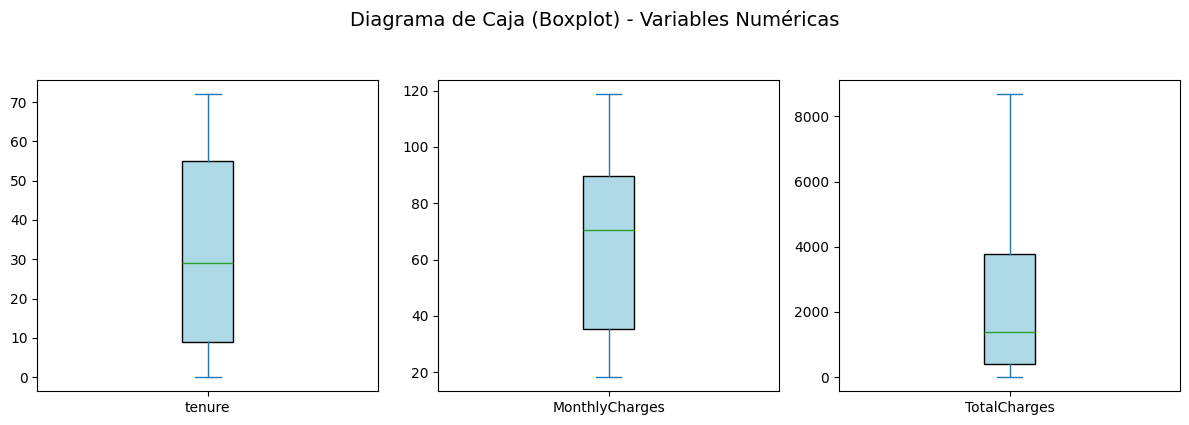

In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("--- ANTES DE LA LIMPIEZA ---")
print("Tipo de TotalCharges:", df['TotalCharges'].dtype)
print("Espacios en blanco en TotalCharges:", (df['TotalCharges'] == ' ').sum())

# 2. Tratamiento de valores anómalos y conversión de tipos en TotalCharges
# Forzamos los espacios en blanco (" ") a NaN utilizando errors='coerce'
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Imputamos los valores nulos resultantes basándonos en la regla de negocio:
# Los clientes con tenure = 0 tienen 0 cargos acumulados.
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("\n--- DESPUÉS DE LA LIMPIEZA ---")
print("Tipo de TotalCharges:", df['TotalCharges'].dtype)
print("Valores nulos totales:", df.isnull().sum().sum())

# 3. Verificación de outliers con el método IQR (Rango Intercuartílico) y Diagrama de Caja
variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in variables_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Cálculo correcto con el operador de multiplicación (*)
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Contar outliers analíticamente
    outliers = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]
    print(f"Outliers detectados en {col}: {len(outliers)}")

# Generación del Diagrama de Caja (Boxplot) exigido por la consigna
df[variables_numericas].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(12, 4),
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='black')
)
plt.suptitle("Diagrama de Caja (Boxplot) - Variables Numéricas", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# Como justificamos teóricamente conservar los extremos por ser comportamientos
# reales del negocio, no filtramos ni eliminamos filas.
df = df.copy()

## Limpieza de Datos y Calidad de Datos - Justificacion

### 1. Tratamiento de Valores Faltantes y Cadenas Anómalas
* **Detección del problema:** La columna `TotalCharges` presentaba 11 celdas con espacios en blanco (`" "`). Al ser detectados como cadenas de texto por Pandas, impedían realizar cualquier tipo de operación matemática o agregación sobre dichos valores.
* **Contexto de negocio:** Se identificó que estos registros anómalos corresponden exclusivamente a clientes con `tenure = 0` (0 meses de antigüedad), es decir, usuarios recién incorporados que aún no completaron su primer ciclo de facturación y, por ende, no poseen cargos históricos acumulados.
* **Criterio de resolución:** Para evitar el sesgo que implicaría eliminar filas (lo que significaría desechar valiosa información de clientes nuevos), se aplicó una conversión a numérico forzando los errores a nulos mediante `pd.to_numeric(..., errors='coerce')`. Dichos nulos se imputaron lógicamente con el valor **`0`**, permitiendo castear formalmente toda la columna al tipo decimal (`float64`).

---

### 2. Gestión de Valores Atípicos (Outliers) mediante el Método IQR
* **Ámbito de aplicación:** El método del Rango Intercuartílico (IQR) se aplicó de forma estricta y exclusiva sobre las únicas tres variables cuantitativas y medibles del conjunto de datos:
  1. **`tenure`** (Meses de antigüedad).
  2. **`MonthlyCharges`** (Cargo mensual en dólares).
  3. **`TotalCharges`** (Cargo total acumulado).
* **Justificación de exclusión del resto de las columnas:**
  * **Variables cualitativas / categóricas** (`gender`, `Contract`, `PaymentMethod`, `InternetService`, `Churn`, etc.): Al tratarse de etiquetas o texto descriptivo, las nociones de cuartiles, promedios y dispersión estadística no tienen sustento matemático aplicable.
  * **`customerID`**: Funciona únicamente como un identificador alfanumérico unívoco y carece de naturaleza métrica.
  * **`SeniorCitizen`**: Aunque esté representada por los dígitos `0` y `1`, conceptualmente opera como una variable binaria categórica (indicador de condición), por lo que no califica para el análisis de valores atípicos continuos.
* **Utilidad analítica:** Aplicar el IQR sobre las variables cuantitativas permitió contrastar matemáticamente la existencia de valores extremos o exagerados (como tarifas o antigüedades fuera de rango lógico) y fundamentar analíticamente su conservación como comportamientos reales del negocio de telecomunicaciones.

# Análisis Exploratorio, Visualización e Integración

#### Análisis Exploratorio de Datos y Estadística Aplicada

- **Análisis Cuantitativo:** determinación e interpretación de medidas de tendencia central, dispersión y análisis de correlación lineal (Pearson/Spearman) para comprender la relación entre variables numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`).
- **Análisis Categórico:** cálculo de frecuencias absolutas, relativas y tablas de contingencia para evaluar la distribución de las características sociodemográficas y de contratación respecto al `Churn`.

,Promedio,Mediana,Moda,Desvío_Estandar,Rango
tenure,32.371149,29.00,1.00,24.559481,72.0
MonthlyCharges,64.761692,70.35,20.05,30.090047,100.5
TotalCharges,2279.734304,1394.55,0.00,2266.794470,8684.8


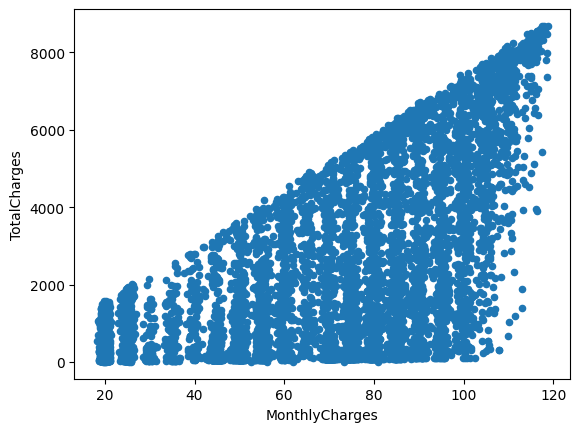

In [8]:
#Alejo ---
# ---------- Medidas de Tendencia Central y Dispersión ----------
cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df_media = df[cols].mean().to_frame("Promedio")
df_median = df[cols].median().to_frame("Mediana")
df_moda = df[cols].mode().iloc[0].to_frame("Moda")
df_desvio = df[cols].std().to_frame("Desvío_Estandar")
df_rango = (df[cols].max() - df[cols].min()).to_frame("Rango")

df_stats = pd.concat([df_media, df_median, df_moda, df_desvio, df_rango], axis=1)

df.plot(x="MonthlyCharges", y="TotalCharges", kind="scatter")
df_stats

In [9]:
#Alejo ---
# ---------- Análisis de correlación lineal ----------
df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


Análisis Categórico:

In [10]:
# ---------- Frecuencias absolutas ----------
# Tabla de frecuencias absolutas y relativas para el Tipo de Contrato vs Churn
abs_contrato = pd.crosstab(df['Contract'], df['Churn'])
display(abs_contrato)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


Text(0, 0.5, 'Cantidad de Clientes')

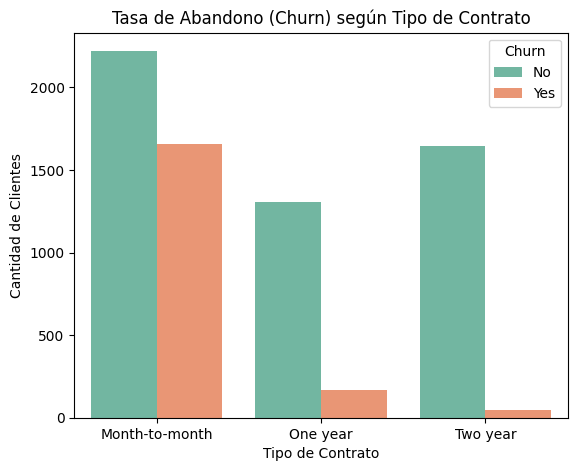

In [11]:
# ---------- Frecuencias relativas / porcentuales por fila ----------
rel_contrato = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
display(round(rel_contrato, 2))
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')
plt.title('Tasa de Abandono (Churn) según Tipo de Contrato')
plt.xlabel('Tipo de Contrato')
plt.ylabel('Cantidad de Clientes')

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


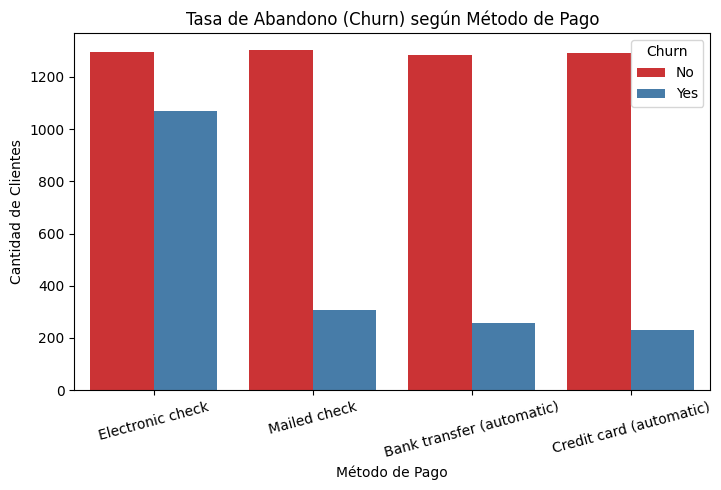

In [12]:
# ---------- Frecuencias relativas porcentuales ----------
#Tabla de contingencia para Método de Pago vs Churn
rel_pago = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100
display(round(rel_pago, 2))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set1')
plt.title('Tasa de Abandono (Churn) según Método de Pago')
plt.xlabel('Método de Pago')
plt.ylabel('Cantidad de Clientes')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## Visualización de Datos

Construcción de un reporte gráfico utilizando Matplotlib y Seaborn que incluya:
Histogramas/KDE de la antigüedad (tenure) y cargos mensuales (MonthlyCharges).

*   Representación gráfica de la matriz de correlación (Heatmap).
*   Diagramas de barras comparativos para evaluar la tasa de cancelación (Churn) según variables categóricas (tipo de contrato y modalidad de pago).
Cada gráfico debe estar acompañado por una breve interpretación analítica orientada al impacto en el negocio.



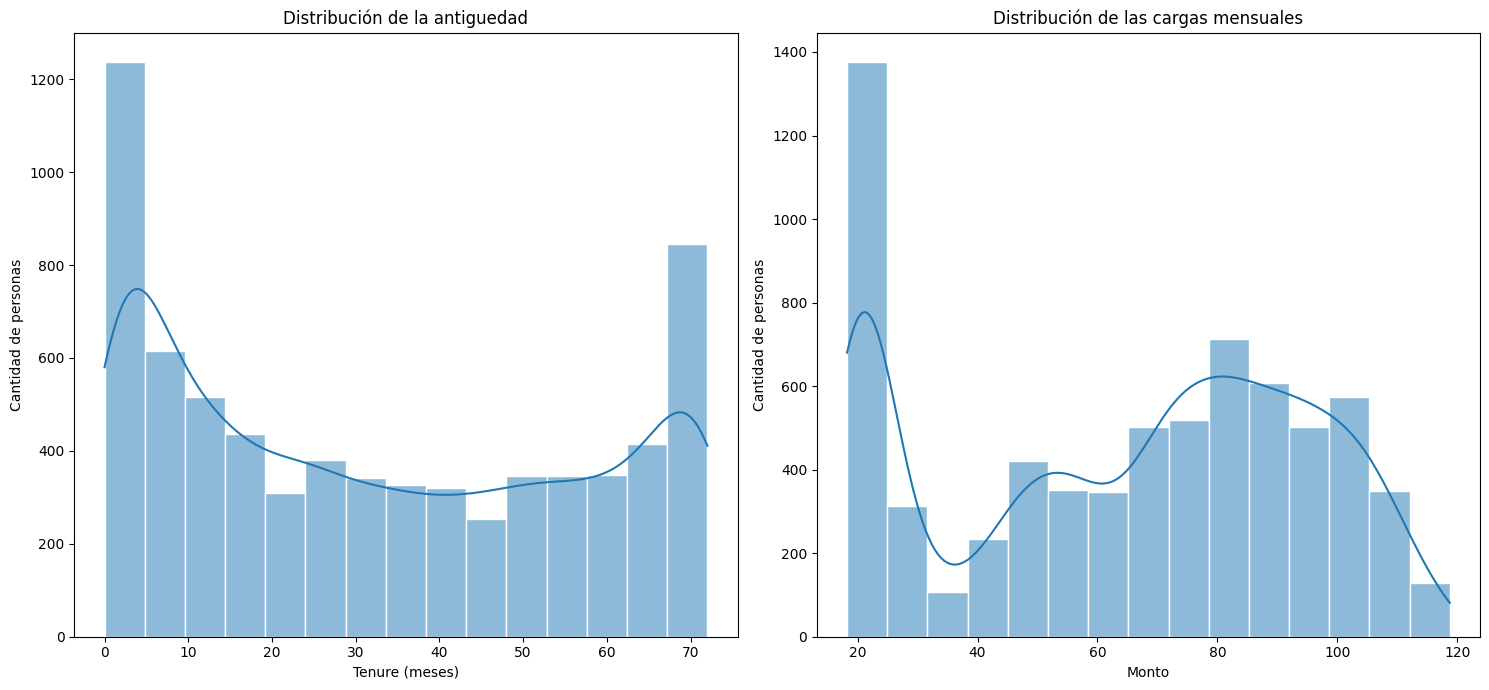

In [13]:
#Alejo ---
# ---------- Histograma de antiguedad ----------
plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)

sns.histplot(data=df, x="tenure", bins=15, edgecolor="white", kde=True)
plt.title("Distribución de la antiguedad")
plt.xlabel("Tenure (meses)")
plt.ylabel("Cantidad de personas")

plt.subplot(1, 2, 2)
sns.histplot(data=df, x="MonthlyCharges", bins=15, edgecolor="white", kde=True)
plt.title("Distribución de las cargas mensuales")
plt.xlabel("Monto")
plt.ylabel("Cantidad de personas")

plt.tight_layout()
plt.show()



## **Distribución de antiguedad**
Se puede observar, en estos gráficos. Que hay dos picos en la población de la distribución de edad. Mostrando como la tasa de cancelación baja drásticamente luego de los primeros 12 meses y vuelve a aumentar enormemente a partir de los 70 meses. El mayor riesgo es dentro de los primeros 6 meses, siendo esta la etapa funadamental para implementar políticas de retención enfocadas a los nuevos clientes. Respecto al pico de los 70 meses o más, recomienda implementar distintas políticas como la promoción y el descuento de los planes anuales.
---
---
## **Distribución de carga mensual**
# Se observa como la gran mayoría de los clientes están en los rangos más bajos de la carga mensual, teniendo picos entre los 70usd y 100usd, para bajar estrepitósamente en los rangos más altos, convendría revisar la relación costo-valor en los planes más caro y analizar más detalladamente la relación de los montos mensuales y las personares que abandonaron el servicio.

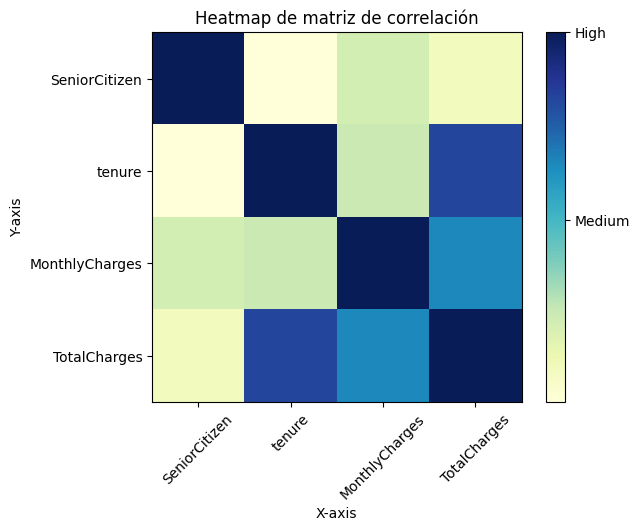

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016567        0.220173      0.103006
tenure               0.016567  1.000000        0.247900      0.826178
MonthlyCharges       0.220173  0.247900        1.000000      0.651174
TotalCharges         0.103006  0.826178        0.651174      1.000000


In [14]:
#Alejo ---
# ---------- Heatmap de matriz de correlación ----------
corr = df.corr(numeric_only=True)
plt.imshow(corr, cmap='YlGnBu')

plt.title("Heatmap de matriz de correlación")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")

cbar = plt.colorbar(ticks=[0, 0.5, 1])
cbar.ax.set_yticklabels(['Low', 'Medium', 'High'])

plt.xticks(range(len(corr.columns)),\
           corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)),
           corr.columns)

plt.show()
print(corr)

## Heatmap de Correlación

### 1. Tratamiento de Valores Faltantes y Cadenas Anómalas
* **Senior Citizen:** La columna apenas logra tener relación con las demás.
Apenas hay relación con  `MonthlyCharges` indicando que puede haber algo de relación entre el rango etario y el pago mensual, pero la relación es demasiado baja.
* **Tenure:** Esta columna no tiene mucha relación con `MonthlyCharges` o `SeniorCitizen`. Pero está infimamente relacionada con `TotalCharges` ya que esta es resultado de la cantidad de meses(`tenure`) por los pagos(`MonthlyCharges`).
* **MonthlyCharges:** El monto de la carga no tiene relación mucha relación con la antiguedad del cliente o su grupo etario. Pero está relacionado con `TotalCharges`debido a que este está compuesto por `MonthlyCharges`.
* **TotalCharges:** Esta columna es apenas afectada por el si los clientes son de tercera edad. Aunque se ve afectada por la antiguedad, medida en meses, y por la carga mensual. `TotalCharges` está compuesta por la multiplicación de ambas.  

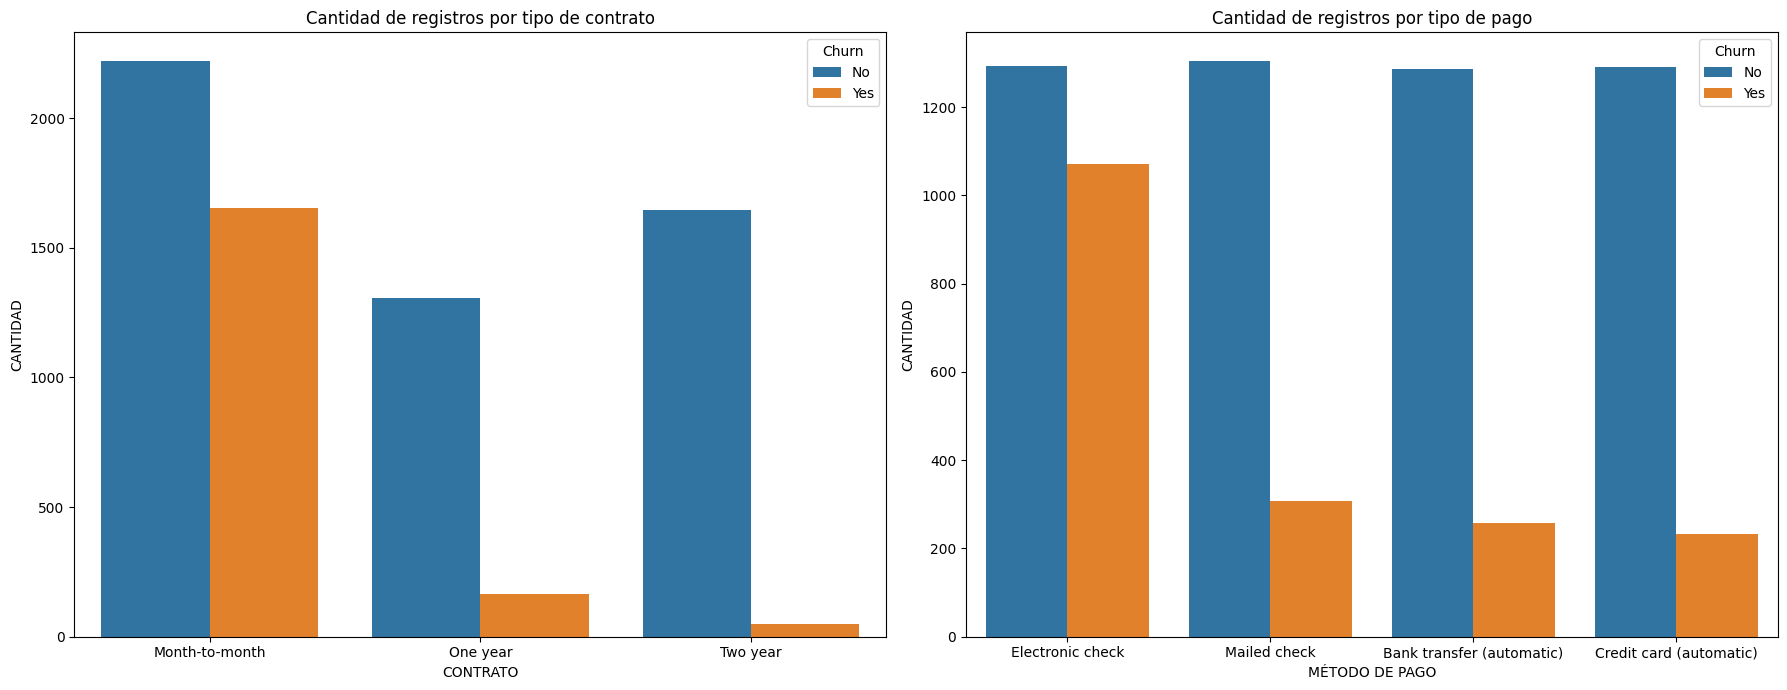

In [15]:
#Alejo ---
# ---------- Diagramas de barras de tasa de cancelación ----------
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 7))
plt.subplot(1, 2, 1)

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Cantidad de registros por tipo de contrato")
plt.xlabel("CONTRATO")
plt.ylabel("CANTIDAD")

plt.subplot(1, 2, 2)
conteo = df["Churn"].value_counts()
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Cantidad de registros por tipo de pago")
plt.xlabel("MÉTODO DE PAGO")
plt.ylabel("CANTIDAD")

plt.tight_layout()
plt.show()


## Diagramas de barras de tasa de cancelación

### 1. Tasa de churn por tipo de contrato
* **Month-to-month:** Se observa que la tasa de cancelación en el contrato mensual es la mayor de todas. La gran mayoría de las cancelaciones totales fueron por este tipo de contrato.
* **One year:** Este tipo de contrato tiene la segunda tasa más baja de cancelaciones, en porcentaje, tiene una gran diferencia abismal con la mensual.
* **Two year:** Este tipo de suscripción es la que tiene la menor tasa de cancelación siendo incluso bastante menor a la anual.

Se puede sacar la conclusión de que los usuarios más viejos, que conocen bien las capacidades del sistema y están lo suficientemente seguros para pagar las suscripciones anuales, son los que tienen, por lejos, las menores tasas de cancelación. Mientras que los clientes nuevos o casuales que tienen contratos mensuales tienen tasas altísimas de cancelación.

### 2. Tasa de churn por tipo de pago
El "Electronic check" es, por lejos, el medio de pago con la mayor tasa de cancelación de las 4 categorías. Mientras que "mailed check", "Bank Transfer(automatic)" y "Credit card(automatic)" tienen números bastante similares en tema de Churn.
Se puede sacar la conclusión que los cheques electrónicos manuales siguen una lógica parecida a los de la cancelación mensual. Normalmente sería usado por clientes nuevos o casuales, que manualmente, están emitiendo estos pagos sin estar muy seguros de su uso para el mes siguiente. Mientras que los cheques, las transferencias y el débito automático son medios usados por usuarios con más antiguedad o seguros del uso que le van a dar a los servicios.

## C. Preprocesamiento y Modelado Predictivo
#### Preprocesamiento de Datos para Modelado
● Transformación de variables categóricas mediante codificación nominal (One-Hot Encoding) u ordinal (Label / Ordinal Encoding).

● Normalización o estandarización (StandardScaler/MinMaxScaler) de atributos
cuantitativos.

● Partición estratificada en conjuntos de entrenamiento y evaluación (train_test_split, proporción 80/20).

**Predicción Numérica: Modelos de Regresión**

Entrenamiento de un modelo básico de Regresión Lineal Simple para estimar una variable continua (por ejemplo, TotalCharges). Evaluación simple mediante el coeficiente de determinación R2 y el Error Medio Absoluto (MAE).

**Predicción Categórica: Modelos de Clasificación**

Entrenamiento de un único modelo de clasificación elemental (por ejemplo, Regresión Logística o Árbol de Decisión) para predecir la variable binaria Churn. Evaluación básica mediante la Matriz de Confusión y la métrica de Exactitud (Accuracy).

In [16]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

#print("Filas y columnas:", df.shape)
#print("Valores faltantes por columna:")
#print(df.isna().sum())

Superficies para entrenamiento:


,tenure
0,1
1,34
2,2
3,45
4,2
...,...
7038,24
7039,72
7040,11
7041,4


Superficies para prueba:


,tenure
8,28
14,25
15,69
17,71
19,21
...,...
7023,63
7025,18
7034,67
7036,12


R²: 0.6700723339739993
MAE: 892.378940559346
Pendiente: 76.72873262004306
Intercepto: -196.8583675132504


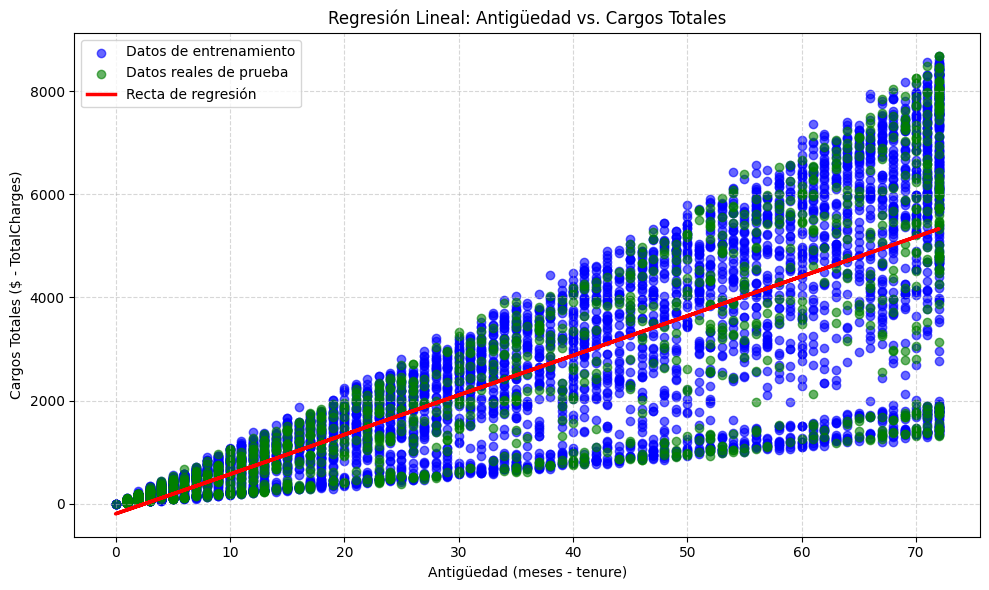

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Selección
datos_regresion = df[["tenure", "TotalCharges"]].dropna()

X = datos_regresion[["tenure"]]
y = datos_regresion["TotalCharges"]

# 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

#Los registros que utilizamos para entrenamiento y para prueba
print("Superficies para entrenamiento:")
display(X_train.sort_index())

print("Superficies para prueba:")
display(X_test.sort_index())


# Entrenamiento.
modelo_regresion = LinearRegression()
modelo_regresion.fit(X_train, y_train)

# Predicciones sobre datos no utilizados para entrenar.
y_pred = modelo_regresion.predict(X_test)

# Evaluación.
print("R²:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

print("Pendiente:", modelo_regresion.coef_[0])
print("Intercepto:", modelo_regresion.intercept_)

# El primer modelo intentará estimar TotalCharges, es decir, el cargo acumulado de un cliente.
# Para comenzar, se utilizó una sola variable predictora: tenure, la antigüedad del cliente en meses.

# ¿Qué estamos evaluando?
# - R² (coeficiente de determinación): indica qué tan bien representa el modelo la variabilidad de los valores observados. Un valor de 1 corresponde a un ajuste perfecto;
# un valor cercano a 0 indica que el modelo aporta poca capacidad explicativa respecto de predecir la media en este conjunto.
# Puede ser negativo si funciona peor que esa referencia.
# - MAE (Error Absoluto Medio): mide cuánto se desvían, en promedio, las predicciones de los valores reales, en las mismas unidades de TotalCharges. Cuanto menor sea, mejor.


#Grafico

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))


# Datos utilizados para entrenar (puntos azules)
plt.scatter(
    X_train["tenure"],
    y_train,
    color="blue",
    alpha=0.6,
    label="Datos de entrenamiento"
)

# Datos reales reservados para prueba (puntos verdes)
plt.scatter(
    X_test["tenure"],
    y_test,
    color="green",
    alpha=0.6,
    label="Datos reales de prueba"
)

# Recta aprendida por el model
plt.plot(
    X,
    modelo_regresion.predict(X),
    color="red",
    linewidth=2.5,
    label="Recta de regresión"
)

plt.xlabel("Antigüedad (meses - tenure)")
plt.ylabel("Cargos Totales ($ - TotalCharges)")
plt.title("Regresión Lineal: Antigüedad vs. Cargos Totales")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# El grafico plasma como la antiguedad impacta en los cargos acumulados.


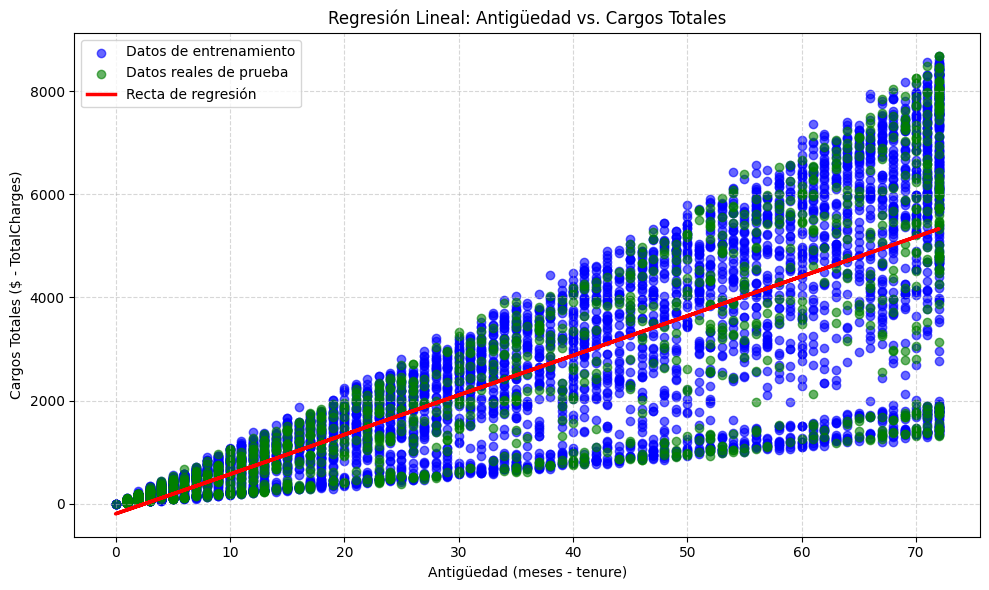

In [18]:
#Grafico para obsevar los datos y la recta creada por el modelo

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))


# Datos utilizados para entrenar (puntos azules)
plt.scatter(
    X_train["tenure"],
    y_train,
    color="blue",
    alpha=0.6,
    label="Datos de entrenamiento"
)

# Datos reales reservados para prueba (puntos verdes)
plt.scatter(
    X_test["tenure"],
    y_test,
    color="green",
    alpha=0.6,
    label="Datos reales de prueba"
)

# Recta aprendida por el model
plt.plot(
    X,
    modelo_regresion.predict(X),
    color="red",
    linewidth=2.5,
    label="Recta de regresión"
)

plt.xlabel("Antigüedad (meses - tenure)")
plt.ylabel("Cargos Totales ($ - TotalCharges)")
plt.title("Regresión Lineal: Antigüedad vs. Cargos Totales")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


Accuracy: 0.8055358410220014
Matriz de confusión:
[[926 109]
 [165 209]]


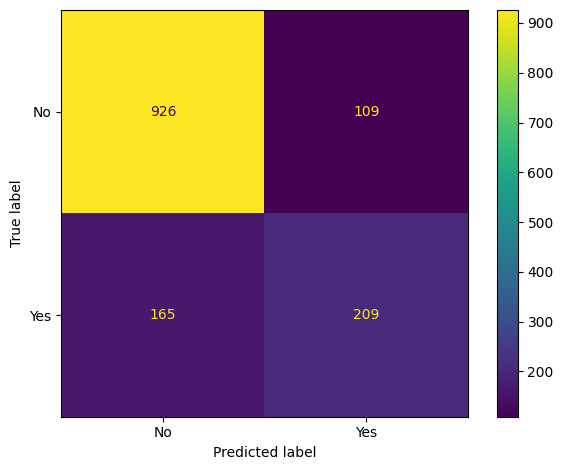

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# ---------------------------------------
#Predecir el abandono: clasificación
#Ahora vamos a resolver un problema distinto: predecir si un cliente abandonará la empresa.

#La variable que queremos predecir es Churn, cuyos valores son Yes y No.
# Utilizaremos Regresión Logística, un modelo de clasificación que estima la probabilidad de pertenecer a una categoría.

# ---------------------------------------

# Variables predictoras y objetivo.
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

# Identificamos automáticamente los tipos de columnas.
columnas_numericas = X.select_dtypes(
    include=["number"]
).columns

columnas_categoricas = X.select_dtypes(
    include=["object", "category"]
).columns

# Preprocesamiento numérico.
transformacion_numerica = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento categórico.
transformacion_categorica = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Aplicamos la transformación adecuada a cada tipo de columna.
preprocesador = ColumnTransformer([
    ("numericas", transformacion_numerica, columnas_numericas),
    ("categoricas", transformacion_categorica, columnas_categoricas)
])

# Modelo completo: preprocesamiento + clasificación.
modelo_clasificacion = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(max_iter=1000))
])

# División estratificada: 80 % entrenamiento y 20 % evaluación.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Entrenamiento.
modelo_clasificacion.fit(X_train, y_train)

# Predicción.
y_pred = modelo_clasificacion.predict(X_test)

# Evaluación.
print("Accuracy:", accuracy_score(y_test, y_pred))

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print("Matriz de confusión:")
print(matriz)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No", "Yes"]
)

visualizacion.plot()
import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

# Como establecimos el orden ["No", "Yes"], la matriz tiene esta estructura:

# Verdaderos negativos: clientes que permanecieron y el modelo identificó correctamente.
# Verdaderos positivos: clientes que abandonaron y el modelo identificó correctamente.
# Falsos positivos: clientes que el modelo predijo que abandonarían, pero permanecieron.
# Falsos negativos: clientes que abandonaron, pero el modelo predijo que permanecerían.

# 926 verdaderos negativos: el cliente no abandonó y el modelo predijo No. Acertó.
# 109 falsos positivos: el cliente no abandonó, pero el modelo predijo Yes. Se equivocó.
# 165 falsos negativos: el cliente abandonó, pero el modelo predijo No. Se equivocó.
# 209 verdaderos positivos: el cliente abandonó y el modelo predijo Yes. Acertó.
# En total, se evaluaron a 1.409 clientes. De ellos, el modelo clasificó correctamente a 1.135.
# El modelo acertó en aproximadamente el 80,55 % de los casos.

# La diferencia entre detectar a quienes se quedan y a quienes se van
# Clientes que permanecieron: de los 1.035 que realmente se quedaron, el modelo identificó correctamente a 926.
# Clientes que abandonaron: de los 374 que realmente se fueron, el modelo identificó correctamente a 209.

# En otras palabras, de cada 100 clientes que realmente abandonaron, el modelo detectó aproximadamente 56 y no detectó 44.

# Exportacion dataset

In [20]:
df.to_csv("dataset_completo_procesado.csv", index=False)